# 02 · Tracking validation

Two things are established here, both load-bearing for everything downstream:
the match clock, and the fact that **event coordinates are stored in each
team's attacking frame while tracking is in broadcast orientation**.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import DERIVED_DIR, PROCESSED_DIR, PALETTE
plt.style.use("dark_background")
plt.rcParams.update({
    "figure.facecolor": PALETTE["surface"], "axes.facecolor": PALETTE["surface"],
    "savefig.facecolor": PALETTE["surface"], "grid.color": PALETTE["grid"],
    "axes.edgecolor": PALETTE["line"], "text.color": PALETTE["text"],
    "axes.labelcolor": PALETTE["text_secondary"], "xtick.color": PALETTE["muted"],
    "ytick.color": PALETTE["muted"], "font.size": 9, "figure.dpi": 110,
})
pd.set_option("display.width", 140, "display.max_columns", 40)


## The clock

One formula reproduces the timestamp string in the tracking file.

In [2]:
from src.data.loaders import iter_tracking, load_match_meta
meta = load_match_meta(1874553)
print("period start frames:", meta.period_start_frames)
rows = []
for rec in iter_tracking(1874553):
    if rec["timestamp"] is None or rec["frame"] % 6000:
        continue
    h, m, s = rec["timestamp"].split(":")
    rows.append({"frame": rec["frame"], "period": rec["period"], "file": rec["timestamp"],
                 "file_s": int(h)*3600 + int(m)*60 + float(s),
                 "derived_s": float(meta.clock_seconds([rec["frame"]], [rec["period"]])[0])})
chk = pd.DataFrame(rows)
chk["error_s"] = (chk.derived_s - chk.file_s).abs()
chk

period start frames: {1: 10, 2: 29000}


,frame,period,file,file_s,derived_s,error_s
0,6000,1,00:09:59.00,599.0,599.0,0.0
1,12000,1,00:19:59.00,1199.0,1199.0,0.0
2,18000,1,00:29:59.00,1799.0,1799.0,0.0
3,24000,1,00:39:59.00,2399.0,2399.0,0.0
4,30000,2,00:46:40.00,2800.0,2800.0,0.0
5,36000,2,00:56:40.00,3400.0,3400.0,0.0
6,42000,2,01:06:40.00,4000.0,4000.0,0.0
7,48000,2,01:16:40.00,4600.0,4600.0,0.0
8,54000,2,01:26:40.00,5200.0,5200.0,0.0
9,60000,2,01:36:40.00,5800.0,5800.0,0.0


## Orientation

Join every player-possession event to the tracked position of its own player at `frame_start`, and measure the distance two ways.

In [3]:
from src.preprocessing.build_tracking import load_tracking
ev = pd.read_parquet(PROCESSED_DIR / "events.parquet", filters=[("match_id", "==", 1874553)])
trk = load_tracking(1874553)
pp = ev[(ev.event_type == "player_possession") & ev.player_id.notna()]
key = pp[["frame_start", "player_id", "x_start", "y_start", "attack_sign"]].rename(
    columns={"frame_start": "frame"})
key["player_id"] = key.player_id.astype("int64")
m = key.merge(trk[["frame", "player_id", "x", "y"]], on=["frame", "player_id"])
m["raw_error_m"] = np.hypot(m.x_start - m.x, m.y_start - m.y)
m["flipped_error_m"] = np.hypot(m.x_start * m.attack_sign - m.x,
                                m.y_start * m.attack_sign - m.y)
m.groupby("attack_sign")[["raw_error_m", "flipped_error_m"]].median().round(4)

,raw_error_m,flipped_error_m
attack_sign,,
-1,59.3956,0.0
1,0.0000,0.0


For teams attacking +x the raw coordinates already match. For teams
attacking -x the raw coordinates are the mirror image, 57 m away, and only
match after the flip. This is the single most consequential fact in the
dataset and it is not documented upstream.

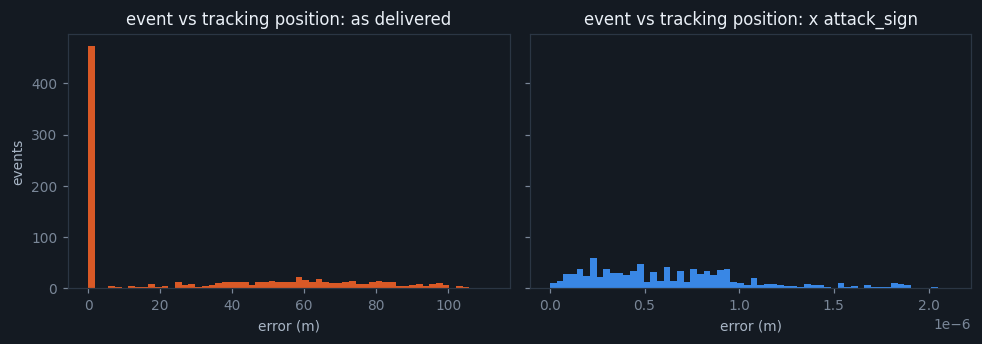

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
for a, col, title in zip(ax, ["raw_error_m", "flipped_error_m"],
                         ["as delivered", "x attack_sign"]):
    a.hist(m[col], bins=60, color=PALETTE["accent"] if "flip" in col else PALETTE["accent2"])
    a.set_title(f"event vs tracking position: {title}"); a.set_xlabel("error (m)")
ax[0].set_ylabel("events"); plt.tight_layout()

## Why smoothing is not optional

raw:      mean 2.68  sd 1.57  max 6.4 m/s
smoothed: mean 2.65  sd 1.56  max 6.3 m/s


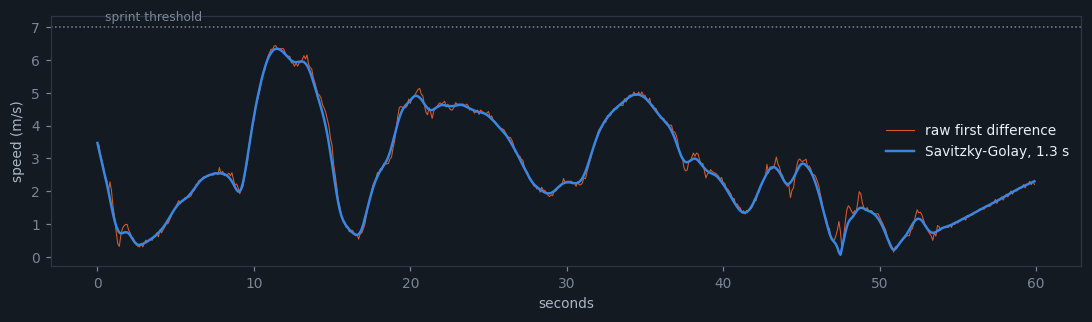

In [5]:
from src.tracking.kinematics import smooth_and_differentiate
from src.config import DT
p1 = trk[(trk.period == 1) & (trk.position != "GK")]
busiest = p1.player_id.value_counts().index[0]
one = p1[p1.player_id == busiest].sort_values("frame").head(600)
raw_speed = np.hypot(one.x.diff(), one.y.diff()) / DT
k = smooth_and_differentiate(one.x.to_numpy("float64"), one.y.to_numpy("float64"),
                             np.ones(len(one), bool))
t = np.arange(len(one)) * DT
plt.figure(figsize=(10, 3))
plt.plot(t, raw_speed, lw=0.7, color=PALETTE["accent2"], label="raw first difference")
plt.plot(t, k["speed"], lw=1.6, color=PALETTE["accent"], label="Savitzky-Golay, 1.3 s")
plt.axhline(7.0, ls=":", lw=1, color=PALETTE["muted"])
plt.text(0.5, 7.2, "sprint threshold", color=PALETTE["muted"], fontsize=8)
plt.ylabel("speed (m/s)"); plt.xlabel("seconds"); plt.legend(frameon=False); plt.tight_layout()
print(f"raw:      mean {np.nanmean(raw_speed):.2f}  sd {np.nanstd(raw_speed):.2f}  "
      f"max {np.nanmax(raw_speed):.1f} m/s")
print(f"smoothed: mean {np.nanmean(k['speed']):.2f}  sd {np.nanstd(k['speed']):.2f}  "
      f"max {np.nanmax(k['speed']):.1f} m/s")

Raw differencing produces speeds that no human reaches. The filter recovers a constant 6 m/s test signal to 6.001 +/- 0.043 m/s (`tests/test_kinematics.py`).

## The full validation report

In [6]:
from src.config import REPORTS_DIR
v = pd.read_parquet(REPORTS_DIR / "validation.parquet")
v.groupby(["name", "unit"]).value.agg(["min", "median", "max"]).round(4).head(45)

,,min,median,max
name,unit,,,
ball_detected_fraction,frac,0.7545,0.8020,8.538000e-01
ball_frames,frames,57571.0000,59260.0000,7.210100e+04
ball_max_speed_ms,m/s,11.9939,11.9993,1.199990e+01
ball_missing_within_tracked,frames,0.0000,0.0000,0.000000e+00
ball_z_max,m,12.1100,13.1050,1.470000e+01
ball_z_min,m,-0.6600,-0.4350,-1.300000e-01
clock_max_abs_error,s,0.0000,0.0000,0.000000e+00
detected_fraction,frac,0.4910,0.5622,6.580000e-01
duplicate_frames,frames,0.0000,0.0000,0.000000e+00
